# **Homework 03 - Machine Learning - Zoomcamp 2026**

## **Imports**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, accuracy_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

## **Download lead scoring dataset**

In [2]:
DATA_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df_leads = pd.read_csv(DATA_URL)

df_leads.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df_leads.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


The target for this classification task is the `converted` column: whether the client signed up to the platform (`1`) or not (`0`).

## **Preparing the dataset**

Check if there are missing values in the features:

In [4]:
df_leads.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

There are missing values in both categorical and numerical features. To handle them, we first separate the columns by type.

The data types in the DataFrame are `str`, `int64` and `float64`. The `str` columns are the categorical features, while the `int64` and `float64` ones are the numerical features. The target `converted` is also stored as `int64`, so we leave it out of the list of numerical features.

In [5]:
target = "converted"

# Get a list with all categorical features
categorical = list(df_leads.select_dtypes(exclude="number").columns)

# Get a list with all numerical features (without the target)
numerical = list(df_leads.select_dtypes(include="number").columns.drop(target))

print(f"Categorical features: {categorical}")
print(f"Numerical features: {numerical}")

Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


Now we replace the missing values with `'NA'` for the categorical features and with `0.0` for the numerical ones:

In [6]:
df_leads[categorical] = df_leads[categorical].fillna("NA")
df_leads[numerical] = df_leads[numerical].fillna(0.0)

df_leads.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## **EDA**

Since we are dealing with a binary classification problem, the target variable must be concentrated only around two possible values:

<Axes: xlabel='converted', ylabel='count'>

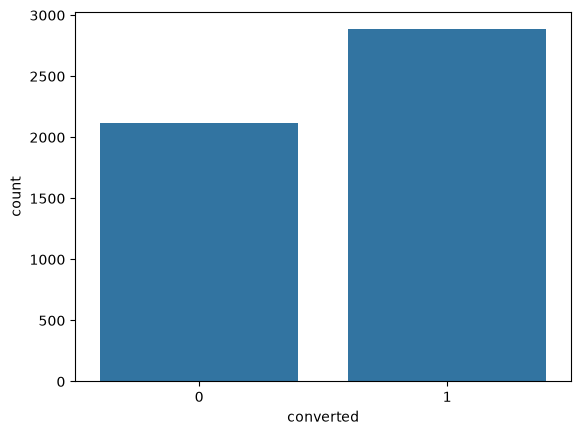

In [7]:
sns.countplot(x=df_leads[target])

In [8]:
df_leads[target].value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

About 58% of the leads converted, so the classes are reasonably balanced.

## **Question 01**

- **Problem statement: What is the most frequent observation (mode) for the column `industry`?**

### **Solution**

There are several ways of calculating the mode, or the most frequent value for a given column of the DataFrame:

In [9]:
df_leads["industry"].mode()

0    technology
Name: industry, dtype: str

In [10]:
df_leads["industry"].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

> **Answer: The mode of the `industry` column is `technology`. Note that `NA`, the value we used to fill the missing entries, is the least frequent one.**

## **Question 02**

- **Problem statement: Create the correlation matrix for the numerical features of your dataset. What are the two features that have the biggest correlation?**

### **Solution**

The correlation is a metric to measure the dependence between two **numerical** variables, so we compute the correlation matrix looking only at the numerical features of our dataset.

In [11]:
# Build the correlation matrix from the numerical features
corr_df = df_leads[numerical].corr()

corr_df

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


For visualization purposes, we plot the correlation matrix using the heatmap method from the Seaborn library:

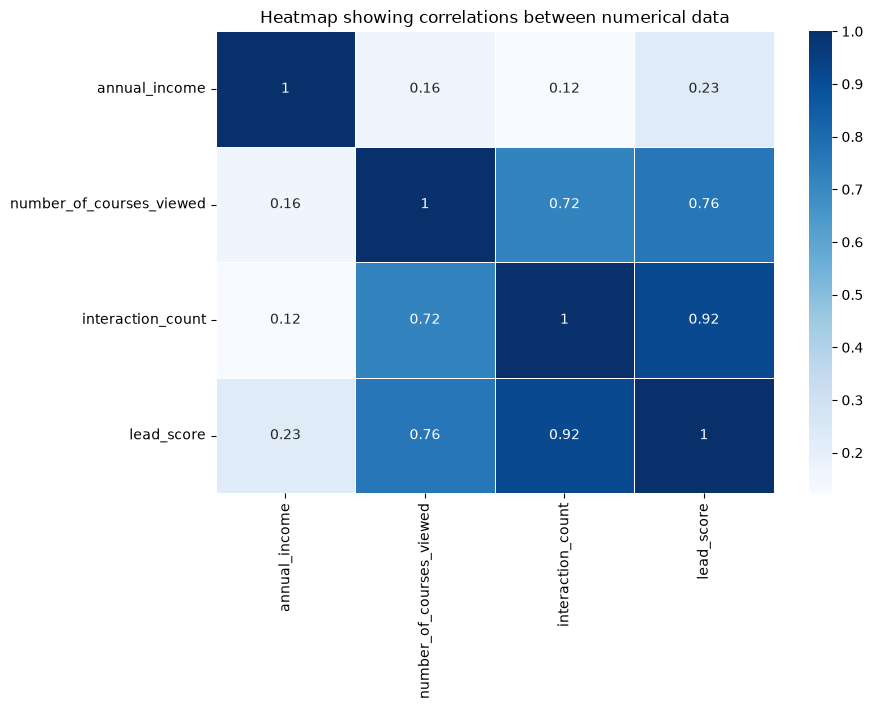

In [12]:
plt.figure(figsize=(9, 6))
sns.heatmap(corr_df, annot=True, linewidths=.5, cmap="Blues")
plt.title("Heatmap showing correlations between numerical data")
plt.show()

Note that the diagonal of the correlation matrix is filled with ones, as it always represents the correlation of a variable with itself.

We can use the `.unstack()` method to reshape the correlation matrix into a Series indexed by pairs of features, which makes it easy to sort the pairs by correlation. Since the matrix is symmetric, each pair appears twice, and the diagonal carries no information, so we keep only the upper triangle:

In [13]:
# Keep only the upper triangle of the matrix, without the diagonal
upper_triangle = np.triu(np.ones(corr_df.shape, dtype=bool), k=1)

corr_df.where(upper_triangle).unstack().dropna().sort_values(ascending=False)

lead_score                interaction_count           0.915746
                          number_of_courses_viewed    0.757204
interaction_count         number_of_courses_viewed    0.721609
lead_score                annual_income               0.229496
number_of_courses_viewed  annual_income               0.161300
interaction_count         annual_income               0.122842
dtype: float64

Looking only at the pairs given as options in the homework:

In [14]:
pairs = [
    ("interaction_count", "lead_score"),
    ("number_of_courses_viewed", "lead_score"),
    ("number_of_courses_viewed", "interaction_count"),
    ("annual_income", "interaction_count"),
]

for feature_1, feature_2 in pairs:
    print(f"{feature_1} and {feature_2}: {corr_df.loc[feature_1, feature_2]:.4f}")

interaction_count and lead_score: 0.9157
number_of_courses_viewed and lead_score: 0.7572
number_of_courses_viewed and interaction_count: 0.7216
annual_income and interaction_count: 0.1228


> **Answer: The two features with the biggest correlation are `interaction_count` and `lead_score`.**

## **Split the dataset**

Here we split the dataset as follows:

- **60% train**

- **20% validation**

- **20% test**

We first allocate 80% of the dataset for training and validation, while the remaining 20% is reserved for testing:

In [15]:
# Split the dataset into 80% (train + val) and 20% test
df_full_train, df_test = train_test_split(df_leads, test_size=0.2, random_state=42)

Now, we need to further split the full training set so that the validation set represents 20% of the entire dataset, and the training set accounts for 60%. In other words, we just need to allocate 25% of the full training set for validation, by the following logic:

- **How much percent of the full training set represents 20% of the whole dataset?**

\begin{equation}
\frac{20\%}{80\%} = 25\%
\end{equation}

In [16]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [17]:
# Reset indexes to get sequential ascending order
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [18]:
# Store the target variable of each dataset division, before deleting it
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

In [19]:
# Delete the target column from train, validation and test datasets
del df_train[target]
del df_val[target]
del df_test[target]

## **Question 03**

- **Problem statement: Which categorical variable has the biggest mutual information score with `converted`? Use the training set only and round the scores to 2 decimals.**

### **Solution**

The `Mutual Information` quantifies how much we learn about the target variable by observing a given categorical variable.

In [20]:
# How much do we know about y by observing x (x being any categorical feature)
for variable in categorical:
    score = mutual_info_score(y_train, df_train[variable])
    print(f"The mutual information between y_train and {variable} is: {round(score, 2)}")

The mutual information between y_train and lead_source is: 0.03
The mutual information between y_train and industry is: 0.0
The mutual information between y_train and employment_status is: 0.02
The mutual information between y_train and location is: 0.0


An alternative and more common approach would be through the `.apply()` method. With this method we can define a function to act directly on each column of the DataFrame:

In [21]:
# Define a function to evaluate mutual information through the .apply() method.
def mutual_info_converted_score(series):
    return mutual_info_score(y_train, series)

In [22]:
# Build a small df to display the value of mutual information for each feature
df_mi = df_train[categorical].apply(mutual_info_converted_score, axis=0)

# Sort from the highest to the lowest mutual information values
df_mi.sort_values(ascending=False).round(2).to_frame(name="MI")

,MI
lead_source,0.03
employment_status,0.02
industry,0.00
location,0.00


> **Answer: `lead_source` has the biggest mutual information score (0.03).**

## **Question 04**

- **Problem statement: What is the accuracy on the validation dataset of a logistic regression trained with one-hot encoded categorical variables?**

### **Solution**

We first convert the DataFrames into lists of dictionaries. This restructuring allows us to use `DictVectorizer()` to build the feature matrices: it applies one-hot encoding to the categorical variables and leaves the numerical ones untouched.

In [23]:
features = categorical + numerical

# Define a list of dictionaries for the training set
dicts_train = df_train[features].to_dict(orient="records")

# Get the list of dictionaries for the validation set
dicts_val = df_val[features].to_dict(orient="records")

In [24]:
# Instantiate DictVectorizer()
dv = DictVectorizer(sparse=False)

# Fit and transform the dicts_train to the vectorizer
X_train = dv.fit_transform(dicts_train)

# Transform the dicts_val to the vectorizer
X_val = dv.transform(dicts_val)

dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [25]:
# Instantiate the Logistic Regression model
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)

# Train the model
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

Now that we've trained the model, we can make predictions on the validation set. Here we will evaluate the `accuracy`, which measures the fraction of correct predictions of the model.

We can evaluate the accuracy in two ways:

**1) Get soft predictions, impose a threshold to get the hard predictions and evaluate the accuracy using its definition:**

In [26]:
# Get the soft predictions of the model
y_pred = model.predict_proba(X_val)[:, 1]

y_pred

array([0.61725691, 0.44364108, 0.60433996, 0.64562246, 0.52214159,
       0.77885722, 0.60698076, 0.54481903, 0.76770971, 0.52765495,
       0.75038798, 0.6470054 , 0.56857815, 0.51044645, 0.59921425,
       0.46620745, 0.62786484, 0.69167143, 0.69082953, 0.59101344,
       0.49964695, 0.55590822, 0.65303933, 0.6079306 , 0.7231576 ,
       0.51616805, 0.56141276, 0.57206269, 0.67043904, 0.55599224,
       0.63613322, 0.70337215, 0.45463513, 0.61897288, 0.65250689,
       0.42775649, 0.63943096, 0.62315373, 0.6602988 , 0.51736304,
       0.53774147, 0.76074014, 0.48326071, 0.74151288, 0.63662375,
       0.41194601, 0.45371292, 0.6417333 , 0.43851314, 0.87060984,
       0.72468973, 0.75643941, 0.5296636 , 0.66736678, 0.50444495,
       0.57644782, 0.72318139, 0.72497254, 0.6507741 , 0.628958  ,
       0.7217776 , 0.59231588, 0.70824617, 0.61451576, 0.49691434,
       0.74445314, 0.52773381, 0.61402574, 0.55979831, 0.59024431,
       0.69368703, 0.72962242, 0.76111566, 0.60744404, 0.52501

In [27]:
# Get the hard predictions using t=0.5
accuracy = ((y_pred >= 0.5).astype("int") == y_val).mean()

accuracy

np.float64(0.645)

**2) Using built-in methods:**

In [28]:
# Evaluate accuracy using built-in method from scikit-learn
y_pred = model.predict(X_val)

original_accuracy = accuracy_score(y_val, y_pred)
original_accuracy

0.645

In [29]:
round(original_accuracy, 2)

0.65

> **Answer: The accuracy on the validation dataset is 0.645, which rounds to 0.65.**

## **Question 05**

- **Problem statement: Using feature elimination, which feature has the smallest difference between the original accuracy and the accuracy without it: `lead_source`, `number_of_courses_viewed` or `interaction_count`?**

### **Solution**

We wrap the steps of Question 04 in a function, so we can train and evaluate a model for any subset of features. The one-hot encoding is redone for each subset, so removing a categorical feature removes all of its encoded columns.

In [30]:
def train_and_evaluate(features: list[str], C: float = 1.0) -> float:
    """Train a logistic regression and return its validation accuracy.

    Args:
        features: Columns used to train the model.
        C: Inverse of the regularization strength.

    Returns:
        The accuracy of the model on the validation set.
    """
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[features].to_dict(orient="records"))
    X_val = dv.transform(df_val[features].to_dict(orient="records"))

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    return accuracy_score(y_val, model.predict(X_val))

In [31]:
# Create an empty DataFrame
accuracy_df = pd.DataFrame(columns=["removed_feature", "accuracy", "difference"])

for i, feature in enumerate(features):
    # Exclude one feature of the set
    subset = [f for f in features if f != feature]

    # Evaluate the accuracy without one of the features
    new_accuracy = train_and_evaluate(subset)

    # Evaluate the difference of accuracies with and without the feature
    diff = original_accuracy - new_accuracy

    # Fill in the empty DataFrame
    accuracy_df.loc[i] = [feature, new_accuracy, diff]

accuracy_df

,removed_feature,accuracy,difference
0,lead_source,0.642,0.003
1,industry,0.645,0.000
2,employment_status,0.645,0.000
3,location,0.645,0.000
4,annual_income,0.724,-0.079
5,number_of_courses_viewed,0.643,0.002
6,interaction_count,0.601,0.044
7,lead_score,0.644,0.001


Looking only at the features given as options in the homework:

In [32]:
options = ["lead_source", "number_of_courses_viewed", "interaction_count"]

accuracy_df[accuracy_df["removed_feature"].isin(options)].sort_values(by="difference")

,removed_feature,accuracy,difference
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.601,0.044


> **Answer: Among the options, `number_of_courses_viewed` has the smallest difference (0.002).**

Note that removing `annual_income` actually *increases* the accuracy (negative difference). This feature is on a much larger scale than the others and we are not scaling the features, which hurts the logistic regression.

## **Question 06**

- **Problem statement: Which value of `C` among `[0.000001, 0.00001, 0.0001, 0.001]` leads to the best accuracy on the validation set?**

### **Solution**

The parameter `C` is the inverse of the regularization strength: the smaller the `C`, the stronger the regularization.

In [33]:
scores = {}
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    scores[C] = round(train_and_evaluate(features, C=C), 3)

df_scores = pd.DataFrame.from_dict(scores, orient="index", columns=["accuracy"])
df_scores.index.name = "C"
df_scores

,accuracy
C,
0.000001,0.598
0.000010,0.598
0.000100,0.613
0.001000,0.645


> **Answer: `C = 0.001` leads to the best accuracy on the validation set (0.645).**